# Обратное распространение ошибки (BackPropagation)

## Обучение нейросети

Обучение нейронной сети - это подбор всех весов сети таким образом, чтобы после передачи на вход нейросети входных значений из обучающей выборки значения на выходе нейросети соответствовали выходным значениям из обучающей выборки.

Изначально весам присваиваются случайные значения.

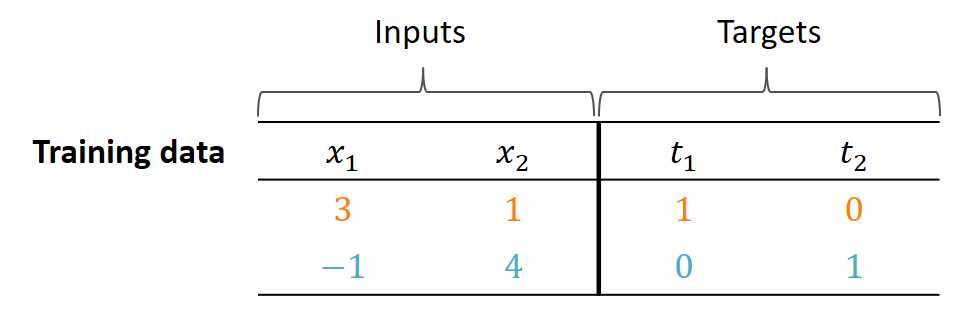

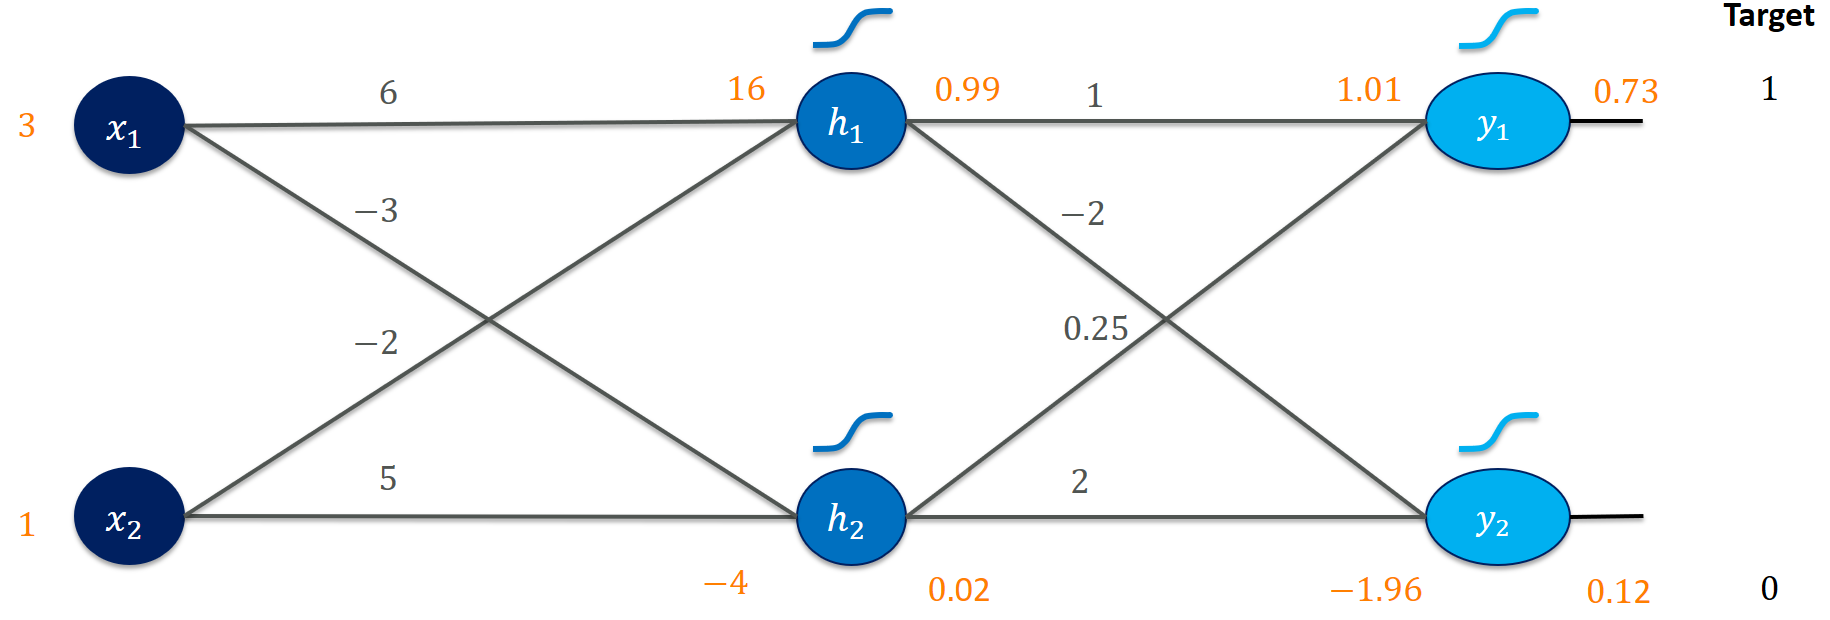

## Проклятие размерности
Предположим, что мы хотим решить следующую задачу:

Нейросеть должна распознавать изображения 100 х 100 пикселей и разделять их на 10 классов.

Для решения задачи мы выбрали нейросеть с 1 скрытым слоем:

1.   Входной слой - 100 * 100 = 10 000 нейронов
2.   Скрытый слой - 15 нейронов
3.   Выходной слой - 10 нейронов

Поскольку мы считаем, что каждый нейрон одного слоя соединяется с каждым нейроном последующего слоя, то количество весов нейросети:

10 000 * 15 + 15 * 10 = 150 150

Если мы представим, что каждый вес сети может принимать значения от 0 до 99 (т.е. всего 100 вариантов), то общее количество вариантов равно:

$100^{150150}$ =

In [ ]:
import sys
sys.set_int_max_str_digits(0)
x = str(100**150150)
print(len(x))

300301


## Прямое распространение и оценка

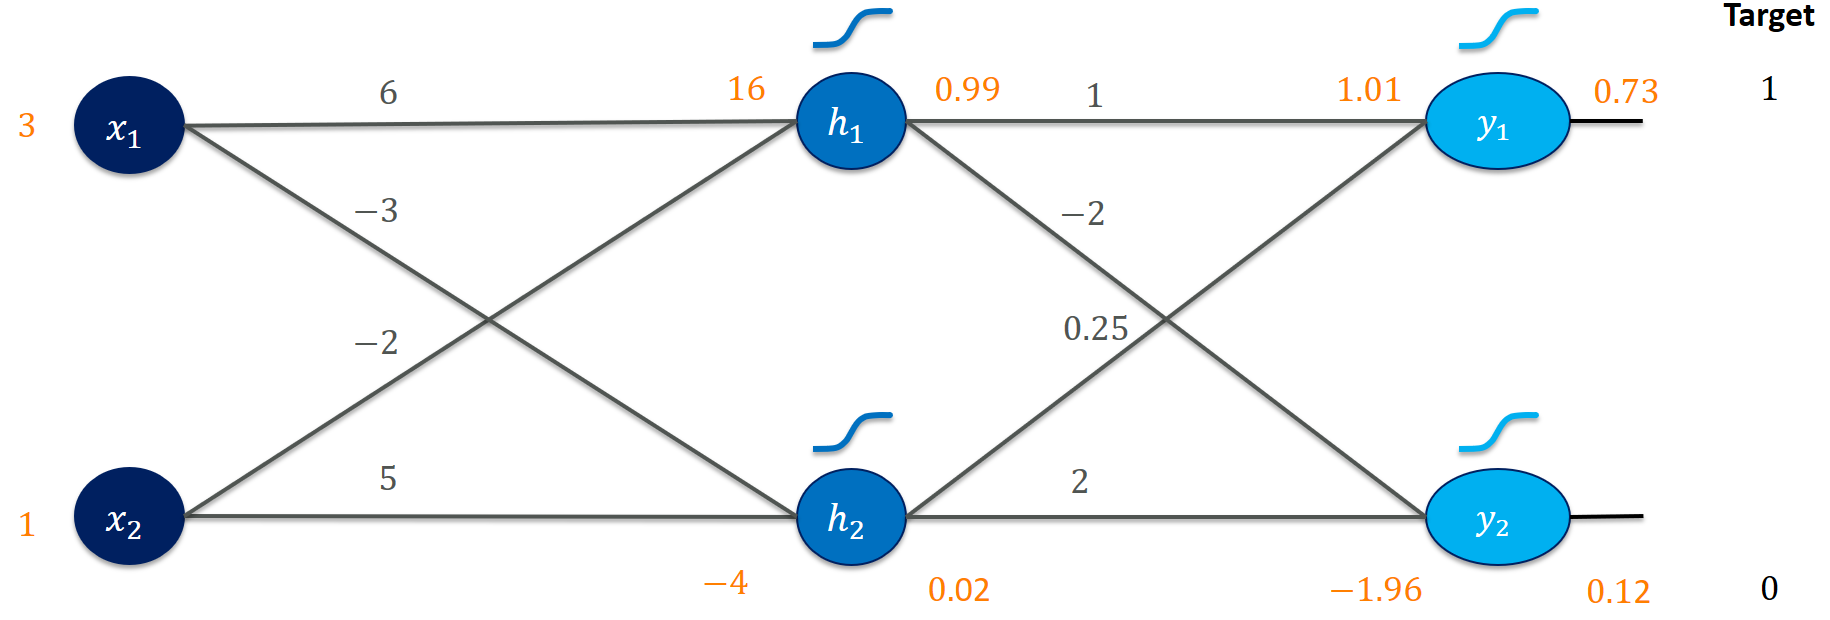

## Обратное распространение ошибки

Функция потерь

$J(ϴ_j) = \frac{1}{2m}\sum\limits_{i=1}^m(h(x^{(i)})-y^{(i)})^2$

Алгоритм градиентного спуска

$ϴ_j := ϴ_j - α\frac{\partial }{\partial ϴ_j}J(ϴ_j)$

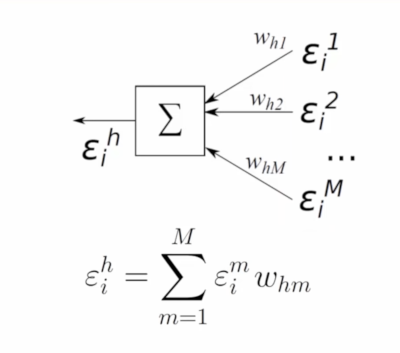

# Пример обучения


Набор данных Fashion MNIST - подписанные изображения предметов  (60 000 изображений, разделенный на 10 классов)

размер изображений 28 х 28 пикселей

цвет - оттенки серого (от 0 до 255)



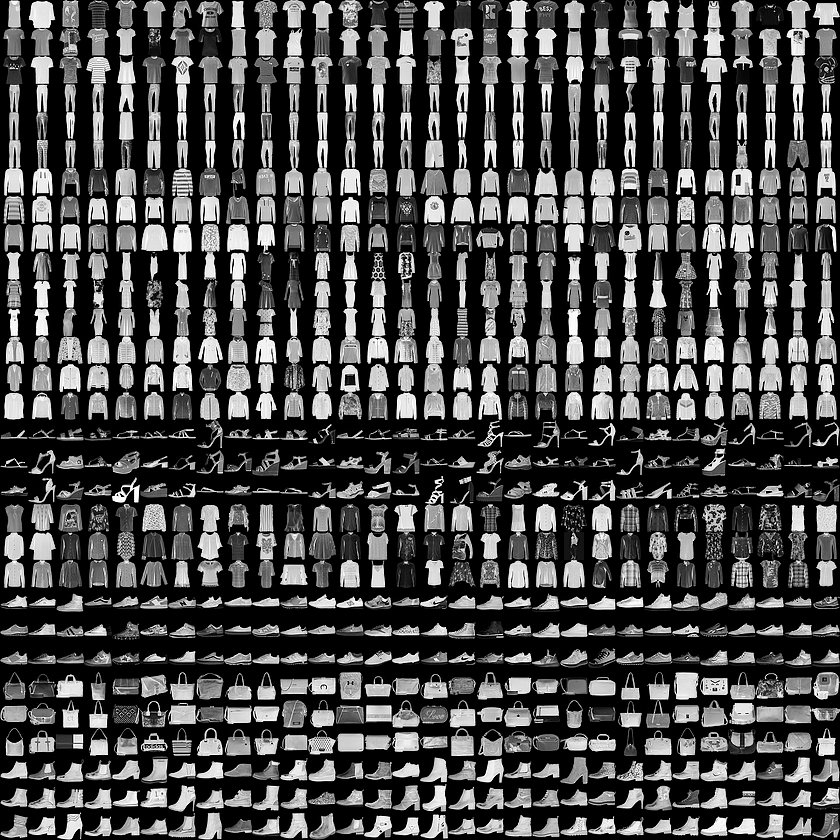

| Класс | Английское описание | Русское описание |
| --- | --- | --- |
| 0 | T-shirt/top | Футболка |
| 1 | Trouser | Брюки |
| 2 | Pullover | Свитер |
| 3 | Dress | Платье |
| 4 | Coat | Пальто |
| 5 | Sandal | Туфли |
| 6 | Shirt | Рубашка |
| 7 | Sneaker | Кроссовки |
| 8 | Bag | Сумка |
| 9 | Ankle boot | Ботинки |

Архитектура сети:

1 Входной слой

1.1 Количество нейронов 28 х 28 = 784

1.2 Значение в одном нейроне - интенсивность цвета (0 - 255)

2 Скрытый слой - 800 нейронов

3 Выходной слой - 10 нейронов, значение - вероятность того, что изображение относится к этому классу (0 - 1)



In [ ]:
# импортируем библиотеки
from keras.datasets import fashion_mnist  # набор данных
from keras.models import Sequential       # последовательна стопка слоев
from keras.layers import Dense, Flatten   # полносвязный и уплощающий слои
from keras.utils import to_categorical    # функции преобразования данных

# загружаем данные
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


## Подготовка входных данных

In [ ]:
print("x_train размерность", x_train.shape)
# преобразование размерности (картинки в 28х28 в вектор 784 чисел)
# x_train = x_train.reshape(60000, 784)
# print("x_train после преобразования", x_train.shape)

x_train размерность (60000, 28, 28)


In [ ]:
# нормализация данных
print("x_train до нормализации", x_train[0][:10])
x_train = x_train / 255
print(" ")
print("x_train после нормализации", x_train[0][:10])

x_train до нормализации [[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0
    0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62
   54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134
  144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178
  107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216
  216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   0   0   0   

## Подготовка выходных данных

In [ ]:
print("y_train до преобразования категорий", y_train[0])
y_train = to_categorical(y_train, 10)
print("y_train после преобразования категорий", y_train[0])

# 0 -> [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
# 1 -> [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
# 4 -> [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]

y_train до преобразования категорий 9
y_train после преобразования категорий [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


## Описываем архитектуру нейросети

In [ ]:
# модель последовательной нейронной сети
model = Sequential()

# добавляем слои
model.add(Flatten(input_shape=(28,28)))
model.add(Dense(800, activation="relu"))
model.add(Dense(10, activation="softmax"))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Подробнее про [функции активации](https://neurohive.io/ru/osnovy-data-science/activation-functions/)

### Relu

Очень быстро работает и выдает хороший результат

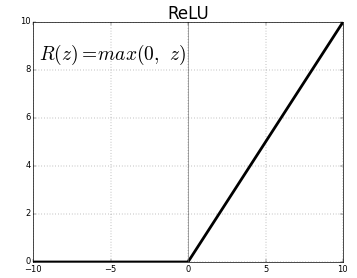

### Softmax

*   Используется для представления вероятности
*   Сумма всех выходных значений нейронов равна 1



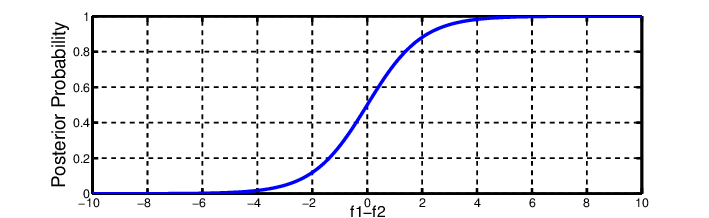

## Настройка модели обучения

In [ ]:
model.compile(loss = 'categorical_crossentropy', optimizer = 'SGD', metrics = ['accuracy'])

Параметры сборки:

*   loss - функция ошибки
*   optimizer - алгоритм оптимизации
*   metrics - метрика качества обучения

categorical_crossentropy - категориальная перекрестная энтропия. Хорошо подходит для задач классификации, если классов больше, чем 2

SGD - стохастический градиентный спуск

метрика качества обучения:

*   accuracy - доля правильных ответов алгоритма
*   precision - точность
*   recall - полнота




In [ ]:
print(model.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 800)            │       628,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         8,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 636,010 (2.43 MB)

 Trainable params: 636,010 (2.43 MB)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
255**(784*800+800*10)

...

## Обучаем сеть

epochs - количество эпох (1 эпоха - это полный проход по всему обучающему набору)

batch_size - размер пакета (количество значений из обучающего набора, после прямого прохода которого модель обновляет веса)

verbose - формат вывода процесса обучения

0 = беззвучный, 1 = шкала прогресса, 2 = одна строка на эпоху

In [ ]:
model.fit(x_train, y_train, batch_size = 200, epochs = 20, verbose = 1)

Epoch 1/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6788 - loss: 1.1171
Epoch 2/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7736 - loss: 0.7175
Epoch 3/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7989 - loss: 0.6303
Epoch 4/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8112 - loss: 0.5830
Epoch 5/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8201 - loss: 0.5523
Epoch 6/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8252 - loss: 0.5298
Epoch 7/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8302 - loss: 0.5125
Epoch 8/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8332 - loss: 0.4986
Epoch 9/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8371 - loss: 0.4873
Epoch 10/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8385 - loss: 0.4778
Epoch 11/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8416 - loss: 0.4698
Epoch 12/20
300/300 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

## Проверяем качество работы

### Запускаем нейросеть на обучающей выборке

In [ ]:
predictions = model.predict(x_train)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [ ]:
index = 50
print(predictions[index])

import numpy as np
print("предсказанное значение", np.argmax(predictions[index]))
print("реальное значение", np.argmax(y_train[index]))

[1.7514953e-04 1.1417716e-03 6.2224870e-05 9.9836713e-01 2.0725527e-04
 6.1917135e-08 4.1615589e-05 2.9224651e-07 4.0412233e-06 5.2332661e-07]
предсказанное значение 3
реальное значение 3


### Запускаем нейросеть на тестовой выборке

In [ ]:
# нормализация данных
x_test = x_test / 255

In [ ]:
predictions = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


In [ ]:
print("предсказанное значение", np.argmax(predictions[7]))
print("реальное значение", y_test[7])

предсказанное значение 6
реальное значение 6


### Запускаем нейросеть на реальных данных

In [ ]:
from google.colab import files
f = files.upload()

Saving брюки.jpg to брюки.jpg


In [ ]:
!ls

sample_data  брюки.jpg


In [ ]:
img_path = 'брюки.jpg'

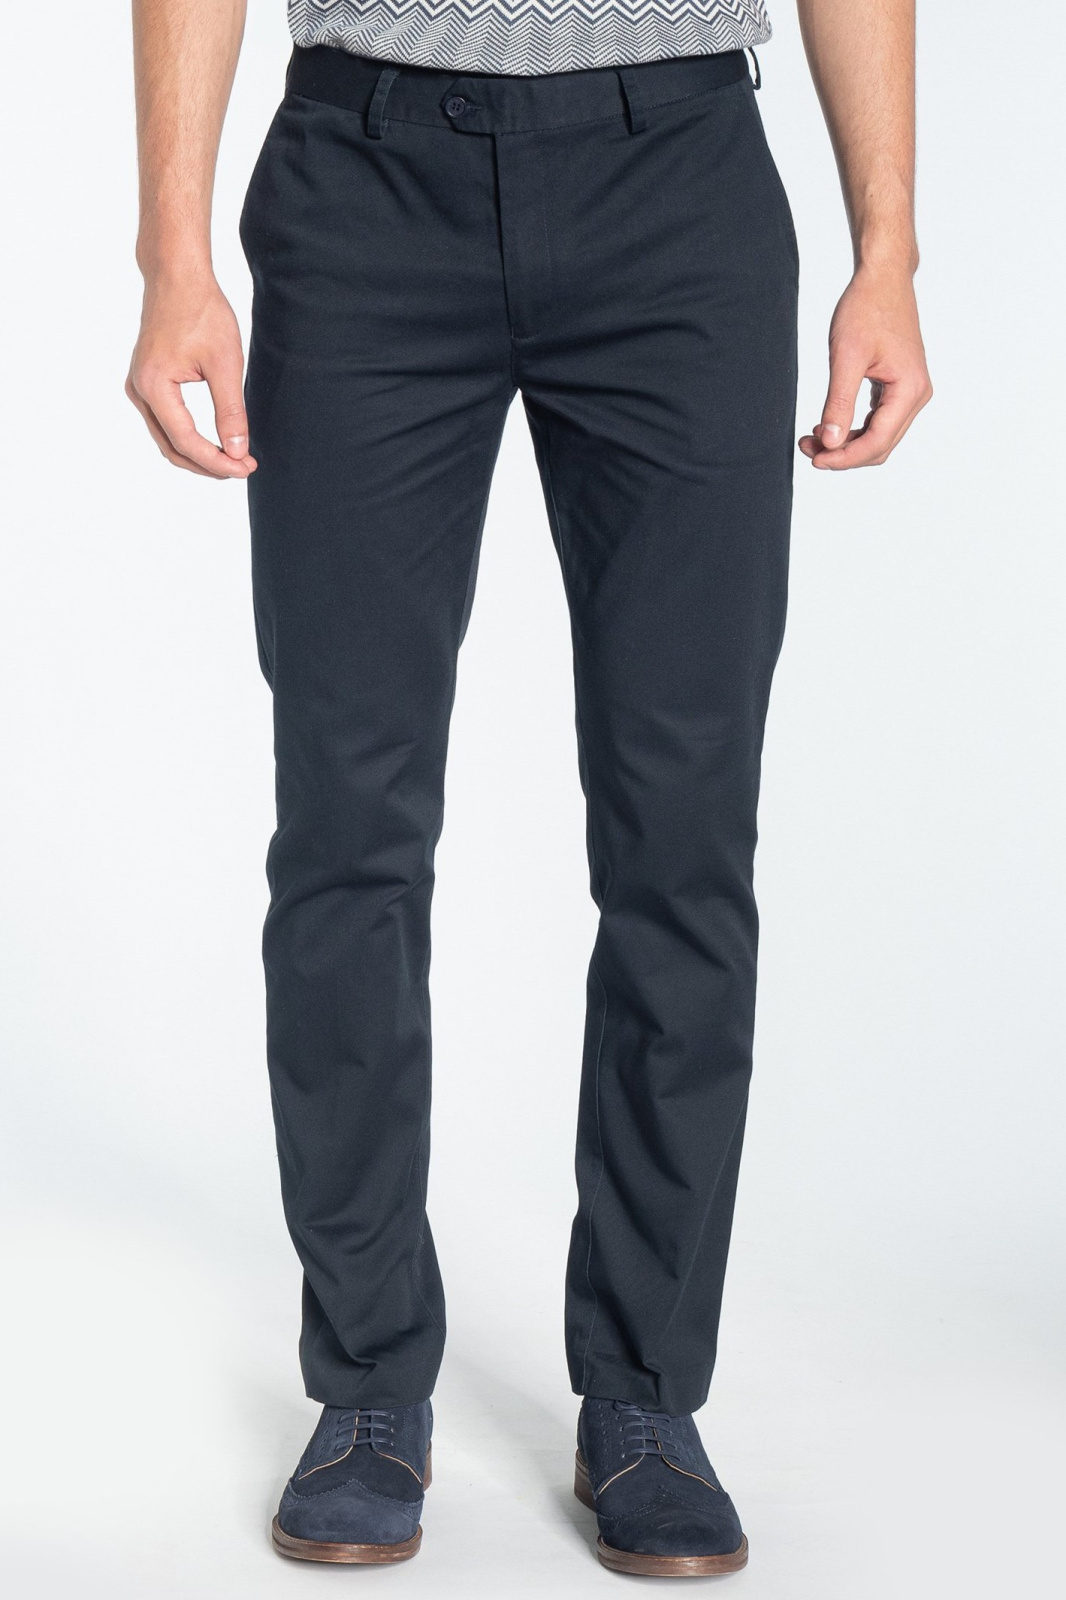

In [ ]:
from IPython.display import Image
Image(img_path)

In [ ]:
import keras
import tensorflow as tf

# загружаем картинку с одновременным преобразованием
img = keras.utils.load_img(img_path, target_size=(28, 28), color_mode = "grayscale")

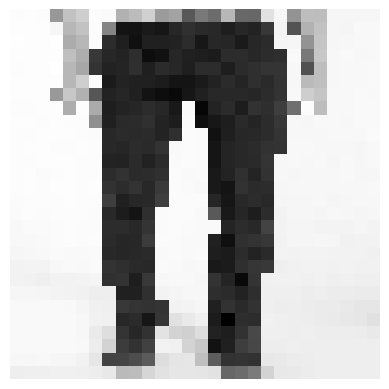

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(img, cmap='gray')          # Отрисовка изображения
plt.axis('off')                       # Отключение ненужных осей
plt.show()

In [ ]:
# Преобразуем картинку в массив
x = keras.utils.img_to_array(img)
print(x.shape)
# Инвертируем изображение
x = 255 - x
# Нормализуем изображение
x /= 255

(28, 28, 1)


In [ ]:
prediction = model.predict(x.reshape(-1,28,28))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step


In [ ]:
# названия классов
classes = ['Футболка', 'Брюки', 'Свитер', 'Платье', 'Пальто', 'Туфли', 'Рубашка', 'Кроссовки', 'Сумка', 'Ботинки']

In [ ]:
prediction = np.argmax(prediction)
print("Номер класса:", prediction)
print("Название класса:", classes[prediction])

Номер класса: 1
Название класса: Брюки


# Проблемы обучения

## Недообучение и переобучение

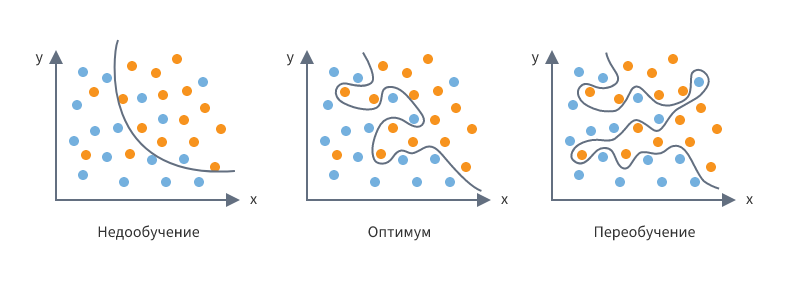

## Подбор гиперпараметров

Параметры:
- веса нейронов

Гиперпараметры:
- количество слоев и нейронов в сети
- количество эпох обучения
- размер мини-выборки
- размер параметра скорости обучения
- архитектура нейросети

## Проблемный датасет

большинство датасетов собирается краулерами, что приводит к большому количеству неоднозначных данных, например "подозреваемый в убийстве", человек с длинными волосами - наркоман

отфильтровать датасет - очень сложно из-за его объема

Камеры никон браковали фотографии с азиатами, поскольку думали, что люди на них моргают